# 03. NV3: Mô phỏng và Đánh giá chính sách phí nhàn rỗi (Idle Fee Policy)

## Mục tiêu nghiên cứu (NV3)
Đánh giá tác động kinh tế và hành vi của các kịch bản áp dụng phí nhàn rỗi (Overstay/Idle Fee):
1. **Kịch bản cơ sở (Baseline):** Không thu phí nhàn rỗi.
2. **Kịch bản 1 (Phí bậc thang đơn giản):** Miễn phí 30 phút đầu sau khi sạc xong (Grace period = 30m), sau đó tính phí \$0.20/phút.
3. **Kịch bản 2 (Phí lũy tiến nghiêm ngặt):** Miễn phí 15 phút đầu, 15–60 phút tính \$0.40/phút, sau 60 phút tính \$1.00/phút.
4. Ước tính doanh thu bổ sung cho đơn vị vận hành trạm và mức độ giảm thiểu thời gian chiếm giữ lãng phí.


In [20]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 150
OUTPUT_DIR = "outputs_nv3_v6"
os.makedirs(OUTPUT_DIR, exist_ok=True)
np.random.seed(42)

### 1. NẠP VÀ AUDIT DỮ LIỆU (TẠO BẢNG AUDIT)


In [21]:
print(">>> CELL 1: NẠP VÀ AUDIT DỮ LIỆU NGHIÊM NGẶT")

FILE_PATH = "../data/processed/sessions_features.parquet"
try:
    df = pd.read_parquet(FILE_PATH) if FILE_PATH.endswith(".parquet") else pd.read_csv(FILE_PATH)
except FileNotFoundError:
    raise FileNotFoundError(f"Không tìm thấy file tại {FILE_PATH}")

rename_dict = {
    'charging_time_hours': 'T_charging', 
    'idle_time_hours': 'T_idle', 
    'total_duration_hours': 'T_total', 
    'Energy (kWh)': 'Energy', 
    'idle_ratio': 'Idle_Ratio'
}
df = df.rename(columns=rename_dict)

required_cols = ['Start Date', 'T_total', 'T_charging', 'T_idle', 'Idle_Ratio', 'Energy', 'User ID', 'Driver Postal Code']
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Thiếu các cột bắt buộc: {missing_cols}")

N_INITIAL = len(df)
audit_log = []

# 1. Kiểm tra ngày tháng
df["Start Date"] = pd.to_datetime(df["Start Date"], errors="coerce")
n_date_err = df["Start Date"].isna().sum()
if n_date_err > 0:
    audit_log.append({
        "Kiểm tra": "Start Date không parse được", 
        "Số dòng": n_date_err, 
        "Tỷ lệ (%)": round(100 * n_date_err / N_INITIAL, 4), 
        "Xử lý": "Loại bỏ khỏi phân tích"
    })

# 2. Ép kiểu số và xử lý vô hạn
numeric_cols = ['T_total', 'T_charging', 'T_idle', 'Idle_Ratio', 'Energy']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df.loc[~np.isfinite(df[col]), col] = np.nan

# 3. Đối chiếu T_idle
df["T_idle_check"] = df["T_total"] - df["T_charging"]
checkable_idle = df[["T_idle", "T_total", "T_charging"]].notna().all(axis=1)
mismatch_idle = checkable_idle & ~np.isclose(df["T_idle"], df["T_idle_check"], atol=1e-4, rtol=0)
audit_log.append({
    "Kiểm tra": "T_idle lệch (T_total - T_charging)", 
    "Số dòng": mismatch_idle.sum(),
    "Tỷ lệ (%)": round(100 * mismatch_idle.sum() / max(checkable_idle.sum(), 1), 4),
    "Xử lý": "Giữ nguyên T_idle gốc, ghi nhận cảnh báo"
})

# 4. Đối chiếu Idle_Ratio
df["Idle_Ratio_check"] = np.where(df["T_total"] > 0, df["T_idle"] / df["T_total"], np.nan)
checkable_ratio = df[["Idle_Ratio", "Idle_Ratio_check"]].notna().all(axis=1)
mismatch_ratio = checkable_ratio & ~np.isclose(df["Idle_Ratio"], df["Idle_Ratio_check"], atol=1e-4, rtol=0)
audit_log.append({
    "Kiểm tra": "Idle_Ratio lệch (T_idle/T_total)", 
    "Số dòng": mismatch_ratio.sum(),
    "Tỷ lệ (%)": round(100 * mismatch_ratio.sum() / max(checkable_ratio.sum(), 1), 4),
    "Xử lý": "Dùng biến tái tính Idle_Ratio_check cho phân tích"
})

# 5. Kiểm tra giá trị âm và T_total <= 0
for col in ['T_idle', 'Energy', 'T_charging']:
    n_neg = (df[col] < 0).sum()
    if n_neg > 0:
        audit_log.append({
            "Kiểm tra": f"{col} âm", 
            "Số dòng": n_neg,
            "Tỷ lệ (%)": round(100 * n_neg / N_INITIAL, 4), 
            "Xử lý": "Loại khỏi phân tích metric đó"
        })

n_nonpos_total = (df["T_total"] <= 0).sum()
if n_nonpos_total > 0:
    audit_log.append({
        "Kiểm tra": "T_total <= 0", 
        "Số dòng": n_nonpos_total,
        "Tỷ lệ (%)": round(100 * n_nonpos_total / N_INITIAL, 4), 
        "Xử lý": "Loại khỏi toàn bộ phân tích thời lượng và tỷ lệ"
    })

audit_df = pd.DataFrame(audit_log)
print("\n--- BẢNG AUDIT DỮ LIỆU (NV3) ---")
print(audit_df.to_markdown(index=False))
audit_df.to_csv(f"{OUTPUT_DIR}/audit_table.csv", index=False)

# Chuyển sang phút
df["T_idle_min"] = df["T_idle"] * 60

# Phân đoạn Pre/Post
POLICY_DATE = pd.Timestamp("2017-08-01")
df["Policy_Period"] = np.where(df["Start Date"] < POLICY_DATE, "Pre", "Post")
df = df.dropna(subset=["Start Date"])

>>> CELL 1: NẠP VÀ AUDIT DỮ LIỆU NGHIÊM NGẶT

--- BẢNG AUDIT DỮ LIỆU (NV3) ---
| Kiểm tra                           |   Số dòng |   Tỷ lệ (%) | Xử lý                                             |
|:-----------------------------------|----------:|------------:|:--------------------------------------------------|
| T_idle lệch (T_total - T_charging) |         0 |           0 | Giữ nguyên T_idle gốc, ghi nhận cảnh báo          |
| Idle_Ratio lệch (T_idle/T_total)   |         0 |           0 | Dùng biến tái tính Idle_Ratio_check cho phân tích |


### 2. PHÂN KHÚC NGƯỜI DÙNG & KIỂM TRA CẤU TRÚC


In [22]:
# ==============================================================================
# CELL 2: PHÂN KHÚC NGƯỜI DÙNG & KIỂM TRA CẤU TRÚC
# ==============================================================================
print("\n>>> CELL 2: PHÂN KHÚC NGƯỜI DÙNG VÀ KIỂM TRA CẤU TRÚC")

user_periods = (
    df.dropna(subset=["User ID"])
      .groupby("User ID")["Policy_Period"]
      .agg(lambda s: set(s))
)
n_pre_only = sum(v == {"Pre"} for v in user_periods)
n_post_only = sum(v == {"Post"} for v in user_periods)
n_both = sum(v == {"Pre", "Post"} for v in user_periods)

print(f" - User chỉ có mặt ở giai đoạn Pre: {n_pre_only:,}")
print(f" - User chỉ có mặt ở giai đoạn Post: {n_post_only:,}")
print(f" - User có mặt ở CẢ 2 giai đoạn (Paired): {n_both:,}")
print("   [Lưu ý] Phân tích chính so sánh các phiên sạc giữa hai giai đoạn Pre/Post,")
print("           không ghép cặp phiên sạc trước-sau của từng User.")
print("           Một số User xuất hiện ở cả hai giai đoạn; Cluster Bootstrap")
print("           lấy mẫu theo User để giữ các phiên thuộc cùng một cụm.")
print("           Kết quả vẫn cần được diễn giải trong bối cảnh khác biệt về thời gian")
print("           và các yếu tố gây nhiễu có thể có.")

# Phân khúc (Dùng cho mô tả)
pre_policy_df = df[df["Policy_Period"] == "Pre"]
user_freq_pre = pre_policy_df.groupby("User ID").size().reset_index(name="Pre_Session_Count")
df = df.merge(user_freq_pre, on="User ID", how="left")
df["Pre_Session_Count"] = df["Pre_Session_Count"].fillna(0)

df["Zip_Clean"] = df["Driver Postal Code"].astype(str).str.extract(r'(\d{5})')[0]
local_zips = ["94301", "94303", "94306", "94304", "94305"]

is_frequent = df["Pre_Session_Count"] >= 10
is_local = df["Zip_Clean"].isin(local_zips)

df["User_Segment"] = np.where(is_frequent & is_local, "Regular", "Casual")
df.loc[df["User ID"].isna() | df["Zip_Clean"].isna(), "User_Segment"] = "Unclassified"

user_strat = pd.crosstab(df["Policy_Period"], df["User_Segment"], normalize="index") * 100
print("\nTỷ lệ phân khúc (%):")
print(user_strat.round(2).to_markdown())
user_strat.to_csv(f"{OUTPUT_DIR}/3.3.2_user_strat.csv", index=False)



>>> CELL 2: PHÂN KHÚC NGƯỜI DÙNG VÀ KIỂM TRA CẤU TRÚC
 - User chỉ có mặt ở giai đoạn Pre: 5,813
 - User chỉ có mặt ở giai đoạn Post: 11,862
 - User có mặt ở CẢ 2 giai đoạn (Paired): 3,766
   [Lưu ý] Phân tích chính so sánh các phiên sạc giữa hai giai đoạn Pre/Post,
           không ghép cặp phiên sạc trước-sau của từng User.
           Một số User xuất hiện ở cả hai giai đoạn; Cluster Bootstrap
           lấy mẫu theo User để giữ các phiên thuộc cùng một cụm.
           Kết quả vẫn cần được diễn giải trong bối cảnh khác biệt về thời gian
           và các yếu tố gây nhiễu có thể có.

Tỷ lệ phân khúc (%):
| Policy_Period   |   Casual |   Regular |   Unclassified |
|:----------------|---------:|----------:|---------------:|
| Post            |    87.46 |       9.6 |           2.93 |
| Pre             |    67.83 |      28.5 |           3.67 |


## 3.Kiểm định Thống kê & Cluster Bootstrap

In [23]:

# ==============================================================================
# CELL 3: KIỂM ĐỊNH THỐNG KÊ
# MWU THAM KHẢO + CLUSTER BOOTSTRAP SUY LUẬN
# ======================================================================
print("\n>>> CELL 3: KIỂM ĐỊNH THỐNG KÊ")

# ------------------------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------------------------
METRICS = ["T_idle_min", "Idle_Ratio_check", "Energy", "T_charging"]

N_BOOT = 2000
BOOTSTRAP_SEED = 42
MIN_VALID_BOOTSTRAP_RATE = 0.95


# ------------------------------------------------------------------------------
# 2. CLIFF'S DELTA
# Positive Delta: Pre values tend to be larger than Post values.
# Negative Delta: Pre values tend to be smaller than Post values.
# ------------------------------------------------------------------------------

def cliffs_delta(pre, post):
    pre = np.asarray(pre, dtype=np.float64)
    post = np.asarray(post, dtype=np.float64)

    pre = pre[np.isfinite(pre)]
    post = post[np.isfinite(post)]

    if len(pre) == 0 or len(post) == 0:
        return np.nan

    u_stat, _ = stats.mannwhitneyu(
        pre,
        post,
        alternative="two-sided",
        method="asymptotic"
    )

    return (2.0 * u_stat) / (len(pre) * len(post)) - 1.0


def interpret_delta(delta):
    if not np.isfinite(delta):
        return "Invalid"

    magnitude = abs(delta)

    if magnitude < 0.147:
        return "Negligible"
    elif magnitude < 0.330:
        return "Small"
    elif magnitude < 0.474:
        return "Medium"
    else:
        return "Large"


# ------------------------------------------------------------------------------
# 3. PREPARE VALID DATA
# ------------------------------------------------------------------------------

def prepare_metric_data(data, metric):
    required_cols = ["User ID", "Policy_Period", "T_total", metric]
    missing_cols = [c for c in required_cols if c not in data.columns]

    if missing_cols:
        raise KeyError(f"Thiếu cột cần thiết: {missing_cols}")

    valid = data[required_cols].copy()

    valid = valid.dropna(
        subset=["User ID", "Policy_Period", "T_total", metric]
    )

    # Chỉ giữ hai giai đoạn cần so sánh
    valid = valid[
        valid["Policy_Period"].isin(["Pre", "Post"])
    ]

    # Đồng bộ với quy tắc audit: tổng thời lượng phải dương
    valid = valid[valid["T_total"] > 0]

    # Loại giá trị không hữu hạn
    numeric_values = valid[["T_total", metric]].to_numpy(dtype=np.float64)
    valid = valid[np.isfinite(numeric_values).all(axis=1)]

    # Quy tắc hợp lệ theo từng metric
    if metric in ["T_idle_min", "Energy"]:
        valid = valid[valid[metric] >= 0]

    elif metric == "T_charging":
        valid = valid[valid[metric] > 0]

    elif metric == "Idle_Ratio_check":
        valid = valid[
            (valid[metric] >= 0) &
            (valid[metric] <= 1)
        ]

    return valid.reset_index(drop=True)


# ------------------------------------------------------------------------------
# 4. FAST CLUSTER BOOTSTRAP FOR CLIFF'S DELTA
#
# Resample users with replacement, retaining all sessions belonging to each
# sampled user. User multiplicities become session weights.
#
# The sorted Post values and search boundaries are computed only once.
# No DataFrame concatenation or repeated Mann-Whitney ranking inside bootstrap.
# ------------------------------------------------------------------------------

def bootstrap_delta_ci(
    valid_data,
    metric,
    n_boot=N_BOOT,
    seed=BOOTSTRAP_SEED
):
    data = valid_data[
        ["User ID", "Policy_Period", metric]
    ].dropna().copy()

    if data.empty:
        return (np.nan, np.nan)

    # Integer codes for users; each user's sessions share the same code
    user_codes, unique_users = pd.factorize(
        data["User ID"],
        sort=False
    )

    n_users = len(unique_users)

    if n_users < 2:
        return (np.nan, np.nan)

    values = data[metric].to_numpy(dtype=np.float64)
    periods = data["Policy_Period"].to_numpy()

    finite_mask = np.isfinite(values)
    values = values[finite_mask]
    periods = periods[finite_mask]
    user_codes = user_codes[finite_mask]

    pre_mask = periods == "Pre"
    post_mask = periods == "Post"

    pre_values = values[pre_mask]
    post_values = values[post_mask]

    pre_users = user_codes[pre_mask]
    post_users = user_codes[post_mask]

    if len(pre_values) == 0 or len(post_values) == 0:
        return (np.nan, np.nan)

    # Sort Post observations once
    post_order = np.argsort(post_values, kind="mergesort")
    post_sorted = post_values[post_order]
    post_users_sorted = post_users[post_order]

    # For each Pre observation, locate Post values less than / equal to it
    left = np.searchsorted(post_sorted, pre_values, side="left")
    right = np.searchsorted(post_sorted, pre_values, side="right")

    rng = np.random.default_rng(seed)
    bootstrap_deltas = np.empty(n_boot, dtype=np.float64)
    n_valid = 0

    for b in range(n_boot):
        # Sample the same number of users, with replacement
        sampled_users = rng.integers(0, n_users, size=n_users)
        user_counts = np.bincount(
            sampled_users,
            minlength=n_users
        )

        # Every session receives the multiplicity of its user
        pre_weights = user_counts[pre_users]
        post_weights_sorted = user_counts[post_users_sorted]

        total_pre_weight = pre_weights.sum()
        total_post_weight = post_weights_sorted.sum()

        # Possible when sampled users contribute sessions to only one period
        if total_pre_weight == 0 or total_post_weight == 0:
            continue

        # Prefix sums of weighted Post observations
        cumulative_post_weights = np.empty(
            len(post_weights_sorted) + 1,
            dtype=np.float64
        )
        cumulative_post_weights[0] = 0.0
        np.cumsum(
            post_weights_sorted,
            out=cumulative_post_weights[1:]
        )

        # Weighted counts of Post < Pre, Post = Pre, and Post > Pre
        less = cumulative_post_weights[left]
        equal = cumulative_post_weights[right] - less
        greater = total_post_weight - cumulative_post_weights[right]

        # Cliff's Delta = P(Pre > Post) - P(Pre < Post)
        numerator = np.sum(pre_weights * (less - greater))
        denominator = total_pre_weight * total_post_weight

        bootstrap_deltas[n_valid] = numerator / denominator
        n_valid += 1

    valid_rate = n_valid / n_boot

    if valid_rate < MIN_VALID_BOOTSTRAP_RATE:
        print(
            f"   [CẢNH BÁO] {metric}: "
            f"{n_valid}/{n_boot} bootstrap hợp lệ "
            f"({valid_rate:.1%}); không báo cáo CI."
        )
        return (np.nan, np.nan)

    ci_lower, ci_upper = np.percentile(
        bootstrap_deltas[:n_valid],
        [2.5, 97.5]
    )

    return float(ci_lower), float(ci_upper)


# ------------------------------------------------------------------------------
# 5. RUN METRIC ANALYSIS
# ------------------------------------------------------------------------------

results = []
raw_pvals = []
tested_metrics = []

for metric_idx, metric in enumerate(METRICS, start=1):
    print(f"\n[{metric_idx}/{len(METRICS)}] Đang xử lý: {metric}")

    valid_df = prepare_metric_data(df, metric)

    pre_values = valid_df.loc[
        valid_df["Policy_Period"] == "Pre", metric
    ].to_numpy(dtype=np.float64)

    post_values = valid_df.loc[
        valid_df["Policy_Period"] == "Post", metric
    ].to_numpy(dtype=np.float64)

    n_pre = len(pre_values)
    n_post = len(post_values)

    n_users_total = valid_df["User ID"].nunique()
    n_users_pre = valid_df.loc[
        valid_df["Policy_Period"] == "Pre", "User ID"
    ].nunique()
    n_users_post = valid_df.loc[
        valid_df["Policy_Period"] == "Post", "User ID"
    ].nunique()

    if n_pre == 0 or n_post == 0:
        print(
            f"   [BỎ QUA] {metric}: "
            f"Pre={n_pre:,}, Post={n_post:,}."
        )
        continue

    # Descriptive effect size
    delta = cliffs_delta(pre_values, post_values)

    # Conventional MWU p-value: reference only because sessions repeat by user
    _, p_value = stats.mannwhitneyu(
        pre_values,
        post_values,
        alternative="two-sided",
        method="asymptotic"
    )

    print(
        f"   Sessions: Pre={n_pre:,}, Post={n_post:,} | "
        f"Users: total={n_users_total:,}, "
        f"Pre={n_users_pre:,}, Post={n_users_post:,}"
    )

    # Cluster bootstrap CI
    ci_lower, ci_upper = bootstrap_delta_ci(
        valid_df,
        metric,
        n_boot=N_BOOT,
        seed=BOOTSTRAP_SEED + metric_idx
    )

    results.append({
        "Metric": metric,
        "N_Pre": n_pre,
        "N_Post": n_post,
        "Users_Pre": n_users_pre,
        "Users_Post": n_users_post,
        "Delta": round(delta, 4) if np.isfinite(delta) else np.nan,
        "CI 95% (Cluster)": (
            f"[{ci_lower:.3f}, {ci_upper:.3f}]"
            if np.isfinite(ci_lower) and np.isfinite(ci_upper)
            else "N/A"
        ),
        "p-value (MWU)*": f"{p_value:.2e}",
        "Mức độ (Cliff)": interpret_delta(delta)
    })

    raw_pvals.append(p_value)
    tested_metrics.append(metric)

    print(
        f"   Delta={delta:.4f} | "
        f"Cluster CI=[{ci_lower:.4f}, {ci_upper:.4f}]"
    )


# ------------------------------------------------------------------------------
# 6. HOLM MULTIPLE-TESTING CORRECTION
# ------------------------------------------------------------------------------

if not results:
    raise ValueError(
        "Không có metric nào đủ dữ liệu ở cả Pre và Post."
    )

reject_holm, pvals_holm, _, _ = multipletests(
    raw_pvals,
    method="holm"
)

for i, result in enumerate(results):
    result["p-value (Holm)"] = f"{pvals_holm[i]:.2e}"
    result["Có ý nghĩa (Holm)"] = (
        "Có" if reject_holm[i] else "Không"
    )

res_df = pd.DataFrame(results)


# ------------------------------------------------------------------------------
# 7. REPORT AND EXPORT
# ------------------------------------------------------------------------------

print("\n" + "=" * 78)
print("KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ")
print("=" * 78)

print("\nGhi chú phương pháp:")
print(
    "1. Cliff's Delta mô tả hướng và mức độ khác biệt thứ hạng "
    "giữa phiên Pre và Post."
)
print(
    "2. Mann-Whitney p-value là kết quả tham khảo: "
    "các phiên của cùng một user không độc lập."
)
print(
    "3. CI 95% được ước lượng bằng cluster bootstrap theo User ID; "
    "lấy mẫu user có hoàn lại và giữ toàn bộ phiên của user được chọn."
)
print(
    "4. CI không chứa 0 gợi ý Delta khác 0 theo phương pháp bootstrap; "
    "đây không phải bằng chứng nhân quả về tác động của chính sách."
)
print(
    "5. Hiệu chỉnh Holm áp dụng cho các p-value MWU tham khảo, "
    "không biến chúng thành kiểm định đã xử lý phụ thuộc theo user."
)

print("\n" + res_df.to_string(index=False))

output_path = f"{OUTPUT_DIR}/3.3.3_stats.csv"
res_df.to_csv(output_path, index=False)

print(f"\nĐã lưu kết quả: {output_path}")



>>> CELL 3: KIỂM ĐỊNH THỐNG KÊ

[1/4] Đang xử lý: T_idle_min
   Sessions: Pre=128,253, Post=123,439 | Users: total=21,441, Pre=9,579, Post=15,628
   Delta=0.1232 | Cluster CI=[0.0930, 0.1512]

[2/4] Đang xử lý: Idle_Ratio_check
   Sessions: Pre=128,253, Post=123,439 | Users: total=21,441, Pre=9,579, Post=15,628
   Delta=0.1229 | Cluster CI=[0.0957, 0.1507]

[3/4] Đang xử lý: Energy
   Sessions: Pre=128,289, Post=123,445 | Users: total=21,441, Pre=9,579, Post=15,628
   Delta=-0.0281 | Cluster CI=[-0.0609, 0.0022]

[4/4] Đang xử lý: T_charging
   Sessions: Pre=128,289, Post=123,445 | Users: total=21,441, Pre=9,579, Post=15,628
   Delta=0.0714 | Cluster CI=[0.0420, 0.1009]

KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ

Ghi chú phương pháp:
1. Cliff's Delta mô tả hướng và mức độ khác biệt thứ hạng giữa phiên Pre và Post.
2. Mann-Whitney p-value là kết quả tham khảo: các phiên của cùng một user không độc lập.
3. CI 95% được ước lượng bằng cluster bootstrap theo User ID; lấy mẫu user có hoàn lại và giữ toàn 

## 4: BUNCHING ANALYSIS & TRỰC QUAN HÓA


>>> CELL 4: BUNCHING ANALYSIS
Lưu ý: Tỷ lệ tính trên tổng số phiên idle hợp lệ của từng giai đoạn.
| Giai đoạn   |   Mẫu số hợp lệ |   Tỷ lệ [15-20p) (%) |   Tỷ lệ [20-25p) (%) |   Bunching_Ratio |   Chênh lệch (%) |
|:------------|----------------:|---------------------:|---------------------:|-----------------:|-----------------:|
| Pre-policy  |          132410 |                 2.97 |                 2.99 |             0.99 |            -0.03 |
| Post-policy |          126956 |                 3.54 |                 3.07 |             1.16 |             0.48 |


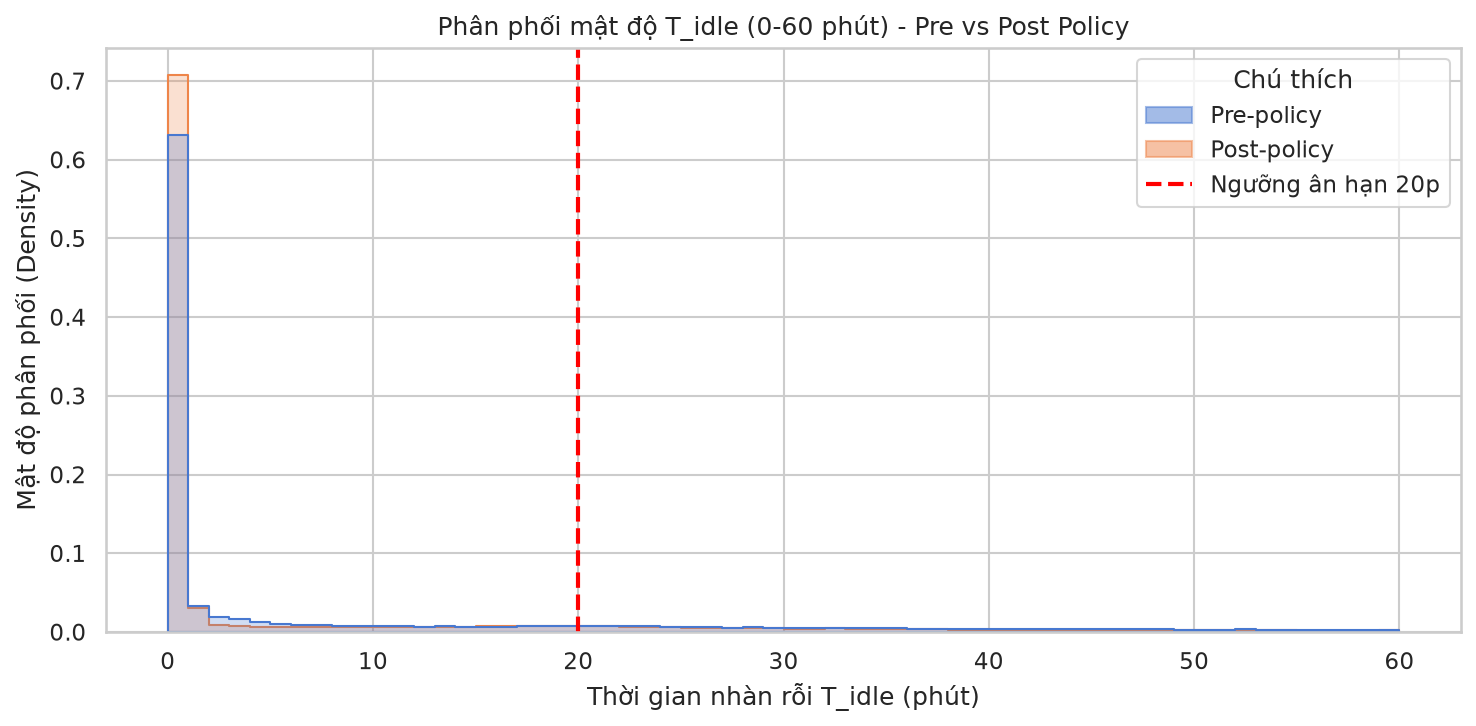


[HOÀN TẤT] Đã lưu kết quả vào outputs_nv3_v6


In [24]:
print("\n>>> CELL 4: BUNCHING ANALYSIS")

valid_idle = df["T_idle_min"].notna() & np.isfinite(df["T_idle_min"]) & (df["T_idle_min"] >= 0)
pre_bunch = df[(df["Policy_Period"] == "Pre") & valid_idle]
post_bunch = df[(df["Policy_Period"] == "Post") & valid_idle]

def rate_pct(count, denominator):
    if denominator == 0: return np.nan
    return 100 * count / denominator

def count_range(data, low, high):
    return ((data["T_idle_min"] >= low) & (data["T_idle_min"] < high)).sum()

rate_pre_15_20 = rate_pct(count_range(pre_bunch, 15, 20), len(pre_bunch))
rate_pre_20_25 = rate_pct(count_range(pre_bunch, 20, 25), len(pre_bunch))
rate_post_15_20 = rate_pct(count_range(post_bunch, 15, 20), len(post_bunch))
rate_post_20_25 = rate_pct(count_range(post_bunch, 20, 25), len(post_bunch))

bunching_table = pd.DataFrame({
    "Giai đoạn": ["Pre-policy", "Post-policy"],
    "Mẫu số hợp lệ": [len(pre_bunch), len(post_bunch)],
    "Tỷ lệ [15-20p) (%)": [rate_pre_15_20, rate_post_15_20],
    "Tỷ lệ [20-25p) (%)": [rate_pre_20_25, rate_post_20_25],
})

bunching_table["Bunching_Ratio"] = bunching_table.apply(
    lambda r: r["Tỷ lệ [15-20p) (%)"] / r["Tỷ lệ [20-25p) (%)"] 
    if pd.notna(r["Tỷ lệ [20-25p) (%)"]) and r["Tỷ lệ [20-25p) (%)"] > 0 else np.nan, axis=1
)
bunching_table["Chênh lệch (%)"] = bunching_table["Tỷ lệ [15-20p) (%)"] - bunching_table["Tỷ lệ [20-25p) (%)"]

print("Lưu ý: Tỷ lệ tính trên tổng số phiên idle hợp lệ của từng giai đoạn.")
print(bunching_table.round(2).to_markdown(index=False))
bunching_table.to_csv(f"{OUTPUT_DIR}/3.3.4_bunching.csv", index=False)

# Ép màu và thứ tự chuẩn
period_order = ["Pre", "Post"]
palette_colors = sns.color_palette("muted")
period_palette = {"Pre": palette_colors[0], "Post": palette_colors[1]}

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = df[(df["T_idle_min"] >= 0) & (df["T_idle_min"] <= 60)]

sns.histplot(
    data=plot_df, x="T_idle_min", hue="Policy_Period",
    hue_order=period_order, palette=period_palette,
    bins=60, stat="density", common_norm=False, element="step", ax=ax
)

# Legend thủ công khớp 100% với màu đã ép
legend_elements = [
    mpatches.Patch(color=period_palette["Pre"], alpha=0.5, label='Pre-policy'),
    mpatches.Patch(color=period_palette["Post"], alpha=0.5, label='Post-policy'),
    Line2D([0], [0], color='red', linestyle='--', lw=2, label='Ngưỡng ân hạn 20p')
]

ax.axvline(20, color="red", linestyle="--", linewidth=2)
ax.set_title("Phân phối mật độ T_idle (0-60 phút) - Pre vs Post Policy")
ax.set_xlabel("Thời gian nhàn rỗi T_idle (phút)")
ax.set_ylabel("Mật độ phân phối (Density)")
ax.legend(handles=legend_elements, title="Chú thích", loc='upper right')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/3.3.4_bunching_plot.png", dpi=300)
plt.show()

print(f"\n[HOÀN TẤT] Đã lưu kết quả vào {OUTPUT_DIR}")